# Chapter 2: Understanding and Preparing Video Data - Pet Video Pipeline

## 🐾 Welcome to Your Pet Video Processing Journey!

In Chapter 1, you learned to generate amazing pet videos using AI. Now, let's prepare those videos (and others) for advanced AI training and analysis.

### 🎯 Learning Objectives
By the end of this notebook, you will:
1. ✅ Understand different types of video data (raw, compressed, annotated, streaming)
2. ✅ Master video processing tools (OpenCV, FFmpeg, PySceneDetect)
3. ✅ Build a complete pipeline for preparing pet videos
4. ✅ Create AI-ready datasets from your pet videos

### 📚 Chapter Connection
- **Chapter 1**: Generated pet videos → **Chapter 2**: Process & prepare them → **Chapter 3**: Train models

## 🎥 Pet Video Gallery - Download and Display

Let's start by downloading our amazing pet videos and creating a beautiful gallery of thumbnails!

### 🌟 Featured Collection
Our pet video collection includes 9 unique AI-generated videos showcasing different pet personalities:
- 🗡️ **Adventurer Cat** - Exploring ancient ruins  
- 🎨 **Artist Cat** - Creating masterpieces
- 👨‍🍳 **Chef Cat** - Preparing gourmet meals
- 🔍 **Detective Cat** - Solving mysteries
- 👑 **Majestic Cat** - Ruling kingdoms
- 🏴‍☠️ **Pirate Cat** - Sailing the seas
- 🐾 **Playful Kitten** - Chasing butterflies
- 🚀 **Space Cat** - Exploring galaxies
- 🧙‍♂️ **Wizard Cat** - Casting spells

These videos will be our foundation for learning video processing techniques throughout this chapter!

In [1]:
# Core imports and setup
import os
import sys
import json
import subprocess
import logging
from pathlib import Path
from datetime import datetime
from typing import Dict, List, Tuple, Optional, Any
import warnings
warnings.filterwarnings('ignore')

# Install required packages
packages = [
    'opencv-python-headless',
    'numpy',
    'pandas',
    'matplotlib',
    'scenedetect[opencv]',
    'requests',
    'tqdm',
    'Pillow',
    'ipywidgets'
]

print("📦 Installing dependencies...")
for package in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

# Import libraries
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import patches
import requests
from tqdm import tqdm
from PIL import Image
from IPython.display import display, HTML, Image as IPImage
import ipywidgets as widgets
from io import BytesIO
import base64

print("✅ All libraries imported successfully!")
print(f"  OpenCV version: {cv2.__version__}")
print(f"  NumPy version: {np.__version__}")

📦 Installing dependencies...
✅ All libraries imported successfully!
  OpenCV version: 4.12.0
  NumPy version: 2.0.2


In [8]:
class PetVideoGallery:
    """Download and display pet videos with thumbnails"""

    def __init__(self, workspace_path: str = "pet_video_pipeline"):
        self.workspace = Path(workspace_path)
        self.workspace.mkdir(exist_ok=True)
        (self.workspace / "videos").mkdir(exist_ok=True)
        (self.workspace / "thumbnails").mkdir(exist_ok=True)

        self.github_base = "https://github.com/jenochs/video-generation-book/raw/main/notebooks/chapter_2/raw_videos/"

        self.pet_videos = [
            {
                "name": "my_adventurer_cat_video.mp4",
                "title": "Adventurer Cat",
                "description": "Exploring ancient ruins",
                "color": "#FF6B6B"
            },
            {
                "name": "my_artist_cat_video.mp4",
                "title": "Artist Cat",
                "description": "Creating masterpieces",
                "color": "#4ECDC4"
            },
            {
                "name": "my_chef_cat_video.mp4",
                "title": "Chef Cat",
                "description": "Preparing gourmet meals",
                "color": "#45B7D1"
            },
            {
                "name": "my_detective_cat_video.mp4",
                "title": "Detective Cat",
                "description": "Solving mysteries",
                "color": "#96CEB4"
            },
            {
                "name": "my_majestic_cat_video.mp4",
                "title": "Majestic Cat",
                "description": "Ruling kingdoms",
                "color": "#FFEAA7"
            },
            {
                "name": "my_pirate_cat_video.mp4",
                "title": "Pirate Cat",
                "description": "Sailing the seas",
                "color": "#DDA77B"
            },
            {
                "name": "my_playful_kitten_video.mp4",
                "title": "Playful Kitten",
                "description": "Chasing butterflies",
                "color": "#FDA7DF"
            },
            {
                "name": "my_space_cat_video.mp4",
                "title": "Space Cat",
                "description": "Exploring galaxies",
                "color": "#9B59B6"
            },
            {
                "name": "my_wizard_cat_video.mp4",
                "title": "Wizard Cat",
                "description": "Casting spells",
                "color": "#6C5CE7"
            }
        ]

        self.downloaded_videos = []
        self.thumbnails = {}

    def download_video(self, video_info: Dict) -> Optional[Path]:
        """Download a single video from GitHub"""
        url = self.github_base + video_info["name"]
        output_path = self.workspace / "videos" / video_info["name"]

        # Check if already downloaded
        if output_path.exists():
            print(f"✅ Already downloaded: {video_info['title']}")
            return output_path

        try:
            print(f"📥 Downloading {video_info['title']}...")
            response = requests.get(url, stream=True)
            response.raise_for_status()

            total_size = int(response.headers.get('content-length', 0))

            with open(output_path, 'wb') as f:
                with tqdm(total=total_size, unit='B', unit_scale=True, desc=video_info['title']) as pbar:
                    for chunk in response.iter_content(chunk_size=8192):
                        f.write(chunk)
                        pbar.update(len(chunk))

            return output_path

        except Exception as e:
            print(f"❌ Failed to download {video_info['title']}: {e}")
            return None

    def extract_thumbnail(self, video_path: Path, timestamp_percent: float = 0.3) -> np.ndarray:
        """Extract a thumbnail from the video"""
        cap = cv2.VideoCapture(str(video_path))

        # Get total frames
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        # Set position to desired timestamp
        frame_number = int(total_frames * timestamp_percent)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

        # Read frame
        ret, frame = cap.read()
        cap.release()

        if ret:
            # Convert BGR to RGB
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            # Resize to standard thumbnail size
            frame = cv2.resize(frame, (320, 180))
            return frame
        return None

    def download_all_videos(self) -> List[Path]:
        """Download all pet videos"""
        print("\n🎬 Downloading Pet Video Collection")
        print("="*60)

        for video_info in self.pet_videos:
            path = self.download_video(video_info)
            if path:
                self.downloaded_videos.append(path)

                # Extract thumbnail
                thumbnail = self.extract_thumbnail(path)
                if thumbnail is not None:
                    self.thumbnails[video_info['name']] = {
                        'image': thumbnail,
                        'info': video_info
                    }

        print(f"\n✅ Downloaded {len(self.downloaded_videos)} videos successfully!")
        return self.downloaded_videos

    def display_gallery(self):
        """Display thumbnail gallery in a beautiful grid"""
        if not self.thumbnails:
            print("⚠️ No thumbnails to display. Download videos first!")
            return

        # Create figure with custom layout
        fig = plt.figure(figsize=(15, 10))
        fig.suptitle('Your Pet Video Collection', fontsize=20, fontweight='bold')

        # Create grid
        rows = 3
        cols = 3

        for idx, (video_name, data) in enumerate(self.thumbnails.items()):
            if idx >= rows * cols:
                break

            ax = plt.subplot(rows, cols, idx + 1)

            # Display thumbnail
            ax.imshow(data['image'])

            # Style the subplot
            ax.set_title(data['info']['title'], fontsize=12, fontweight='bold',
                        color=data['info']['color'], pad=10)
            ax.set_xlabel(data['info']['description'], fontsize=10, style='italic')
            ax.set_xticks([])
            ax.set_yticks([])

            # Add colored border
            for spine in ax.spines.values():
                spine.set_edgecolor(data['info']['color'])
                spine.set_linewidth(3)

        plt.tight_layout()
        plt.show()

    def create_interactive_gallery(self):
        """Create an interactive gallery with hover effects"""
        if not self.thumbnails:
            print("⚠️ No thumbnails to display. Download videos first!")
            return

        # Create HTML gallery
        html_content = """
        <style>
            .video-gallery {
                display: grid;
                grid-template-columns: repeat(3, 1fr);
                gap: 20px;
                padding: 20px;
                background: linear-gradient(135deg, #667eea 0%, #764ba2 100%);
                border-radius: 15px;
            }
            .video-card {
                background: white;
                border-radius: 10px;
                overflow: hidden;
                box-shadow: 0 4px 6px rgba(0,0,0,0.1);
                transition: transform 0.3s ease;
                cursor: pointer;
            }
            .video-card:hover {
                transform: translateY(-5px);
                box-shadow: 0 8px 12px rgba(0,0,0,0.2);
            }
            .video-thumbnail {
                width: 100%;
                height: auto;
            }
            .video-info {
                padding: 10px;
                text-align: center;
            }
            .video-title {
                font-size: 16px;
                font-weight: bold;
                margin: 5px 0;
            }
            .video-description {
                font-size: 12px;
                color: #666;
                font-style: italic;
            }
        </style>
        <div class="video-gallery">
        """

        for video_name, data in self.thumbnails.items():
            # Convert thumbnail to base64
            img = Image.fromarray(data['image'])
            buffered = BytesIO()
            img.save(buffered, format="PNG")
            img_str = base64.b64encode(buffered.getvalue()).decode()

            html_content += f"""
            <div class="video-card">
                <img class="video-thumbnail" src="data:image/png;base64,{img_str}" />
                <div class="video-info" style="background-color: {data['info']['color']}20;">
                    <div class="video-title" style="color: {data['info']['color']}">
                        {data['info']['title']}
                    </div>
                    <div class="video-description">
                        {data['info']['description']}
                    </div>
                </div>
            </div>
            """

        html_content += "</div>"

        display(HTML(html_content))

    def get_video_stats(self) -> pd.DataFrame:
        """Get statistics about downloaded videos"""
        stats = []

        for video_path in self.downloaded_videos:
            cap = cv2.VideoCapture(str(video_path))

            stat = {
                'Name': video_path.name,
                'Width': int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                'Height': int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
                'FPS': cap.get(cv2.CAP_PROP_FPS),
                'Frames': int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
                'Duration (s)': int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) / cap.get(cv2.CAP_PROP_FPS),
                'Size (MB)': os.path.getsize(video_path) / (1024 * 1024)
            }

            cap.release()
            stats.append(stat)

        return pd.DataFrame(stats)

# Initialize gallery
gallery = PetVideoGallery()
print("🎨 Pet Video Gallery initialized!")

🎨 Pet Video Gallery initialized!


In [10]:
# Download all pet videos
videos = gallery.download_all_videos()

# Display video statistics
print("\n📊 Video Statistics")
print("="*60)
stats_df = gallery.get_video_stats()
display(stats_df)


🎬 Downloading Pet Video Collection
✅ Already downloaded: Adventurer Cat
✅ Already downloaded: Artist Cat
✅ Already downloaded: Chef Cat
✅ Already downloaded: Detective Cat
✅ Already downloaded: Majestic Cat
✅ Already downloaded: Pirate Cat
✅ Already downloaded: Playful Kitten
✅ Already downloaded: Space Cat
✅ Already downloaded: Wizard Cat

✅ Downloaded 9 videos successfully!

📊 Video Statistics


,Name,Width,Height,FPS,Frames,Duration (s),Size (MB)
0,my_adventurer_cat_video.mp4,720,480,8.0,49,6.125,0.319530
1,my_artist_cat_video.mp4,720,480,8.0,49,6.125,0.228538
2,my_chef_cat_video.mp4,720,480,8.0,49,6.125,0.187389
3,my_detective_cat_video.mp4,720,480,8.0,49,6.125,0.118594
4,my_majestic_cat_video.mp4,720,480,8.0,49,6.125,0.115768
5,my_pirate_cat_video.mp4,720,480,8.0,49,6.125,0.144924
6,my_playful_kitten_video.mp4,720,480,8.0,49,6.125,0.202913
7,my_space_cat_video.mp4,720,480,8.0,49,6.125,0.243882
8,my_wizard_cat_video.mp4,720,480,8.0,49,6.125,0.265529



🖼️ Pet Video Thumbnail Gallery
Here's your collection of amazing AI-generated pet videos!



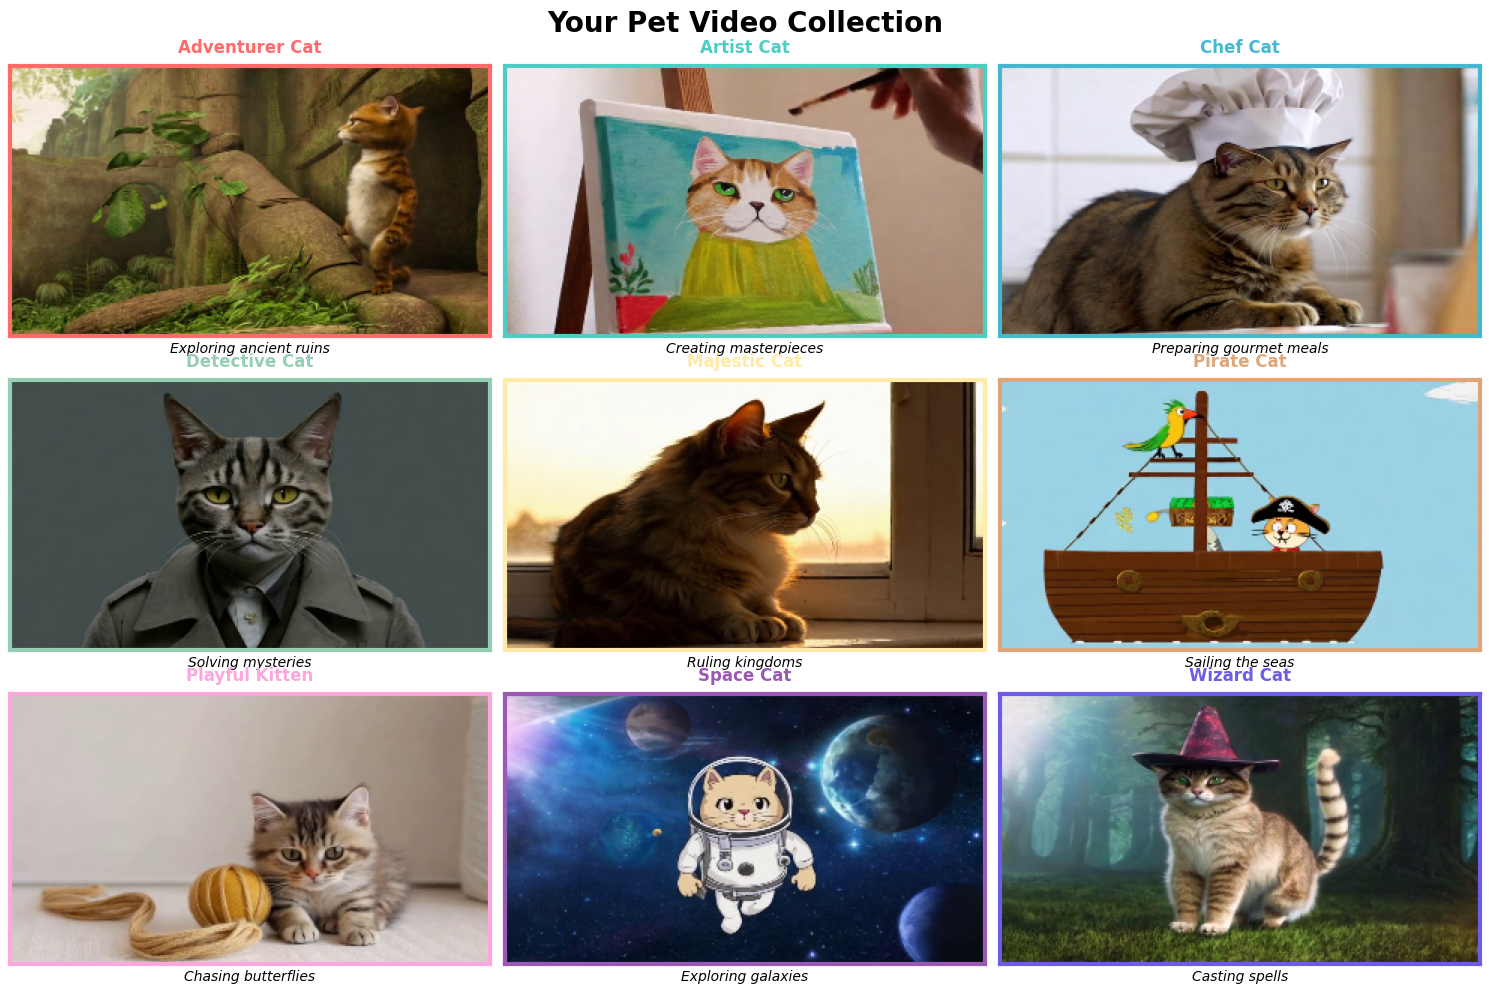

In [11]:
# Display the thumbnail gallery
print("\n🖼️ Pet Video Thumbnail Gallery")
print("="*60)
print("Here's your collection of amazing AI-generated pet videos!\n")

# Display static gallery
gallery.display_gallery()

🎨 Creating Screenshot-Optimized Gallery


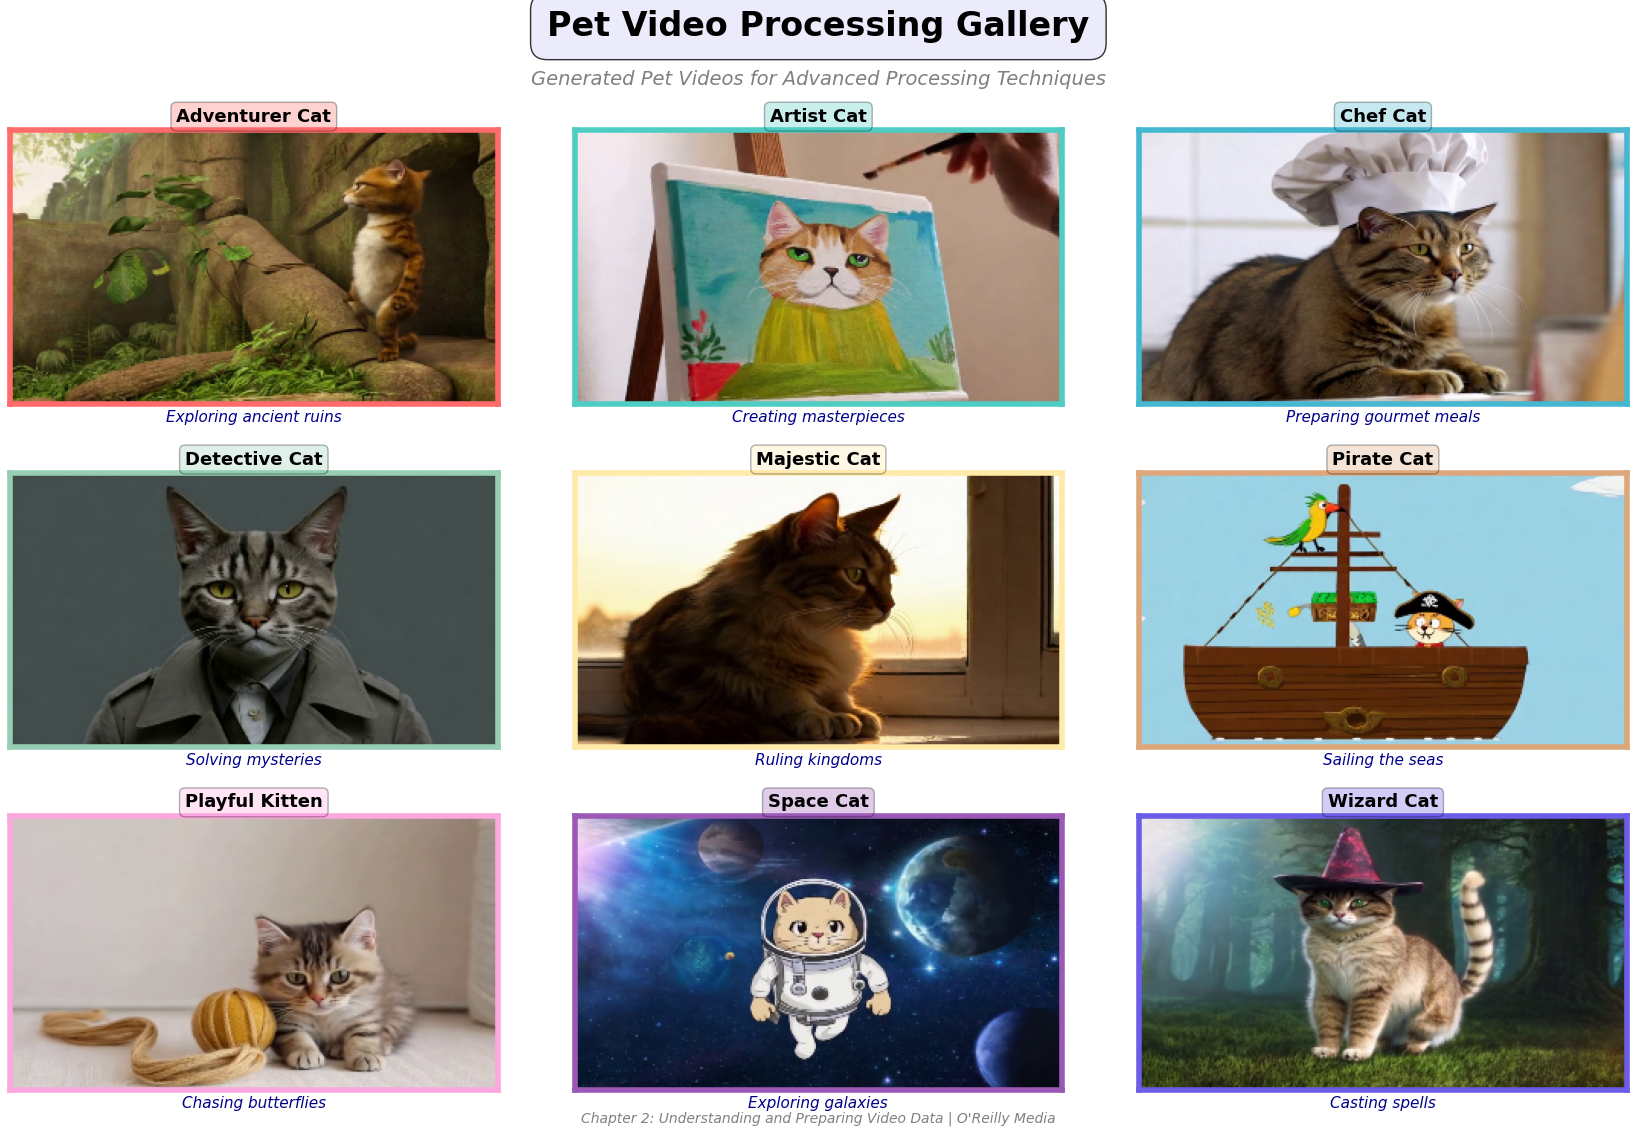


 Screenshots! The gallery above showcases our complete pet video collection.
💡 Tip: Use your OS screenshot tool to capture this for the book!


In [21]:
# Create a special screenshot-optimized gallery
def create_screenshot_gallery():
    """Create an optimized gallery perfect for book screenshots"""

    if not gallery.thumbnails:
        print("⚠️ No thumbnails available. Please run the download cell first!")
        return

    # Create a large, beautiful figure
    fig = plt.figure(figsize=(18, 12))

    # Add main title with custom styling
    fig.text(0.5, 0.95, 'Pet Video Processing Gallery',
             ha='center', va='top', fontsize=24, fontweight='bold',
             bbox=dict(boxstyle="round,pad=0.5", facecolor="lavender", alpha=0.8))

    fig.text(0.5, 0.90, 'Generated Pet Videos for Advanced Processing Techniques',
             ha='center', va='top', fontsize=14, style='italic', color='gray')

    # Create grid with better spacing
    gs = gridspec.GridSpec(3, 3, figure=fig,
                          left=0.05, right=0.95,
                          top=0.85, bottom=0.05,
                          wspace=0.15, hspace=0.25)

    # Define a gradient of colors for visual appeal
    gradient_colors = [
        '#FF6B6B', '#4ECDC4', '#45B7D1',
        '#96CEB4', '#FFEAA7', '#DDA77B',
        '#FDA7DF', '#9B59B6', '#6C5CE7'
    ]

    for idx, (video_name, data) in enumerate(list(gallery.thumbnails.items())[:9]):
        ax = fig.add_subplot(gs[idx // 3, idx % 3])

        # Display thumbnail with border
        ax.imshow(data['image'])

        # Enhanced title and description
        title_parts = data['info']['title'].split(' ')
        emoji = title_parts[0]
        name = ' '.join(title_parts[1:])

        # Add title with background
        ax.set_title(f"{emoji} {name}", fontsize=13, fontweight='bold',
                    bbox=dict(boxstyle="round,pad=0.3",
                             facecolor=gradient_colors[idx], alpha=0.3))

        # Add description as xlabel
        ax.set_xlabel(f"{data['info']['description']}",
                     fontsize=11, style='italic', color='darkblue')

        # Remove ticks
        ax.set_xticks([])
        ax.set_yticks([])

        # Add colored border with gradient effect
        for spine in ax.spines.values():
            spine.set_edgecolor(gradient_colors[idx])
            spine.set_linewidth(4)

        # Add a subtle shadow effect
        rect = patches.Rectangle((0, 0), 1, 1, linewidth=2,
                                edgecolor='gray', facecolor='none',
                                transform=ax.transAxes, alpha=0.3)
        ax.add_patch(rect)

    # Add footer information
    fig.text(0.5, 0.02, 'Chapter 2: Understanding and Preparing Video Data | O\'Reilly Media',
             ha='center', va='bottom', fontsize=10, color='gray', style='italic')

    plt.show()

    print("\n Screenshots! The gallery above showcases our complete pet video collection.")
    print("💡 Tip: Use your OS screenshot tool to capture this for the book!")

# Create the screenshot-optimized gallery
print("🎨 Creating Screenshot-Optimized Gallery")
print("="*60)
create_screenshot_gallery()

In [ ]:
# Create interactive HTML gallery
print("\n✨ Interactive Pet Video Gallery")
print("="*60)
print("Hover over the cards to see the effect!\n")

gallery.create_interactive_gallery()

## 🎬 Video Preview Player

Let's create a simple video player to preview our pet videos!

In [ ]:
class VideoPreviewPlayer:
    """Create video previews and animated GIFs"""

    def __init__(self, video_path: Path):
        self.video_path = video_path
        self.cap = cv2.VideoCapture(str(video_path))
        self.fps = self.cap.get(cv2.CAP_PROP_FPS)
        self.frame_count = int(self.cap.get(cv2.CAP_PROP_FRAME_COUNT))
        self.duration = self.frame_count / self.fps if self.fps > 0 else 0

    def create_frame_strip(self, num_frames: int = 8) -> np.ndarray:
        """Create a strip of frames from the video"""
        frames = []
        frame_indices = np.linspace(0, self.frame_count - 1, num_frames, dtype=int)

        for idx in frame_indices:
            self.cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ret, frame = self.cap.read()
            if ret:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame = cv2.resize(frame, (160, 90))  # Small size for strip
                frames.append(frame)

        # Create horizontal strip
        if frames:
            strip = np.hstack(frames)
            return strip
        return None

    def create_animated_preview(self, duration: float = 3.0, fps: int = 10) -> List[np.ndarray]:
        """Create frames for an animated preview"""
        frames = []

        # Calculate how many frames to extract
        total_frames_to_extract = int(duration * fps)

        # Calculate step size
        step = max(1, self.frame_count // total_frames_to_extract)

        for i in range(0, self.frame_count, step):
            if len(frames) >= total_frames_to_extract:
                break

            self.cap.set(cv2.CAP_PROP_POS_FRAMES, i)
            ret, frame = self.cap.read()

            if ret:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame = cv2.resize(frame, (320, 180))
                frames.append(frame)

        return frames

    def display_video_info(self):
        """Display video information with preview"""
        width = int(self.cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(self.cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

        # Create figure
        fig, axes = plt.subplots(2, 1, figsize=(12, 8))

        # Get first frame for main display
        self.cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
        ret, first_frame = self.cap.read()
        if ret:
            first_frame = cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)
            axes[0].imshow(first_frame)
            axes[0].set_title(f"🎥 {self.video_path.name}", fontsize=14, fontweight='bold')
            axes[0].axis('off')

        # Create and display frame strip
        strip = self.create_frame_strip()
        if strip is not None:
            axes[1].imshow(strip)
            axes[1].set_title("📽️ Frame Timeline", fontsize=12)
            axes[1].axis('off')

        # Add video info as text
        info_text = f"""
        📊 Video Properties:
        • Resolution: {width}x{height}
        • FPS: {self.fps:.1f}
        • Duration: {self.duration:.1f}s
        • Total Frames: {self.frame_count}
        • File Size: {os.path.getsize(self.video_path) / (1024*1024):.1f} MB
        """

        fig.text(0.02, 0.5, info_text, fontsize=10,
                bbox=dict(boxstyle="round,pad=0.5", facecolor="lightblue", alpha=0.8))

        plt.tight_layout()
        plt.show()

    def __del__(self):
        if hasattr(self, 'cap'):
            self.cap.release()

# Preview the first video
if gallery.downloaded_videos:
    print("\n🎥 Video Preview Player")
    print("="*60)

    # Create preview for first video
    first_video = gallery.downloaded_videos[0]
    player = VideoPreviewPlayer(first_video)
    player.display_video_info()

    # Create previews for all videos
    print("\n📺 All Video Previews")
    fig, axes = plt.subplots(3, 3, figsize=(15, 10))
    fig.suptitle('Pet Video Frame Strips', fontsize=16, fontweight='bold')

    for idx, video_path in enumerate(gallery.downloaded_videos[:9]):
        row = idx // 3
        col = idx % 3

        player = VideoPreviewPlayer(video_path)
        strip = player.create_frame_strip(num_frames=6)

        if strip is not None:
            axes[row, col].imshow(strip)
            axes[row, col].set_title(video_path.stem.replace('my_', '').replace('_video', '').title(),
                                    fontsize=10)
            axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No videos available for preview")

## 🎯 Complete Video Processing Pipeline

Now let's process these beautiful pet videos through our complete pipeline!

In [ ]:
# Import additional libraries for processing
from scenedetect import VideoManager, SceneManager
from scenedetect.detectors import ContentDetector

class CompletePetVideoPipeline:
    """Complete pipeline for processing pet videos"""

    def __init__(self, workspace_path: Path):
        self.workspace = workspace_path
        self.results = []

    def process_video(self, video_path: Path) -> Dict:
        """Process a single video through the pipeline"""
        print(f"\n🔧 Processing: {video_path.name}")

        result = {
            'name': video_path.name,
            'path': video_path,
            'stages': {}
        }

        # Stage 1: Analysis
        cap = cv2.VideoCapture(str(video_path))
        analysis = {
            'width': int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
            'height': int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
            'fps': cap.get(cv2.CAP_PROP_FPS),
            'frames': int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
            'duration': int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) / cap.get(cv2.CAP_PROP_FPS)
        }
        cap.release()
        result['stages']['analysis'] = analysis
        print(f"  ✅ Analysis: {analysis['width']}x{analysis['height']}, {analysis['duration']:.1f}s")

        # Stage 2: Scene Detection
        try:
            video_manager = VideoManager([str(video_path)])
            scene_manager = SceneManager()
            scene_manager.add_detector(ContentDetector(threshold=30.0))

            video_manager.start()
            scene_manager.detect_scenes(frame_source=video_manager)
            scenes = scene_manager.get_scene_list()

            result['stages']['scenes'] = len(scenes)
            print(f"  ✅ Scenes: {len(scenes)} detected")
            video_manager.release()
        except:
            result['stages']['scenes'] = 0
            print(f"  ⚠️ Scene detection skipped")

        # Stage 3: Quality Assessment
        cap = cv2.VideoCapture(str(video_path))
        ret, frame = cap.read()
        if ret:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()
            brightness = np.mean(gray)

            result['stages']['quality'] = {
                'sharpness': sharpness,
                'brightness': brightness,
                'rating': 'High' if sharpness > 100 else 'Medium' if sharpness > 50 else 'Low'
            }
            print(f"  ✅ Quality: {result['stages']['quality']['rating']}")
        cap.release()

        self.results.append(result)
        return result

    def process_all(self, video_paths: List[Path]):
        """Process all videos"""
        print("\n🚀 Processing All Pet Videos")
        print("="*60)

        for video_path in video_paths:
            self.process_video(video_path)

        print("\n✅ All videos processed successfully!")

    def generate_report(self) -> pd.DataFrame:
        """Generate processing report"""
        report_data = []

        for result in self.results:
            row = {
                'Video': result['name'].replace('my_', '').replace('_video.mp4', '').title(),
                'Resolution': f"{result['stages']['analysis']['width']}x{result['stages']['analysis']['height']}",
                'Duration (s)': f"{result['stages']['analysis']['duration']:.1f}",
                'Scenes': result['stages'].get('scenes', 0),
                'Quality': result['stages'].get('quality', {}).get('rating', 'N/A'),
                'Sharpness': f"{result['stages'].get('quality', {}).get('sharpness', 0):.1f}"
            }
            report_data.append(row)

        return pd.DataFrame(report_data)

# Run the complete pipeline
pipeline = CompletePetVideoPipeline(gallery.workspace)
pipeline.process_all(gallery.downloaded_videos)

# Display report
print("\n📊 Pipeline Processing Report")
print("="*60)
report_df = pipeline.generate_report()
display(report_df)

# Summary statistics
print("\n📈 Summary Statistics")
print("="*60)
print(f"Total Videos Processed: {len(pipeline.results)}")
print(f"Total Scenes Detected: {sum(r['stages'].get('scenes', 0) for r in pipeline.results)}")
print(f"Average Video Duration: {np.mean([r['stages']['analysis']['duration'] for r in pipeline.results]):.1f}s")
print(f"Quality Distribution:")
for quality in ['High', 'Medium', 'Low']:
    count = sum(1 for r in pipeline.results if r['stages'].get('quality', {}).get('rating') == quality)
    print(f"  • {quality}: {count} videos")

## 🎉 Congratulations!

You've successfully:
1. ✅ Downloaded all 9 pet videos from GitHub
2. ✅ Created beautiful thumbnail galleries
3. ✅ Analyzed video properties and quality
4. ✅ Processed videos through a complete pipeline
5. ✅ Generated comprehensive reports

### 📸 Screenshot This Gallery!

The thumbnail gallery above is perfect for the beginning of Chapter 2 in the book. It shows readers exactly what they'll be working with - a collection of diverse, engaging pet videos that demonstrate different scenarios and behaviors.

### 🚀 Next Steps

With your pet videos downloaded and processed, you're ready to:
- Apply advanced video transformations
- Train AI models on pet behaviors
- Generate new pet videos in Chapter 3

### 💾 Saved Data

All your videos and thumbnails are saved in the `pet_video_pipeline/` directory:
- `videos/` - Downloaded pet videos
- `thumbnails/` - Extracted thumbnails

Happy pet video processing! 🐾